# Inteligência Artificial para Estimativa de Risco de Inundação
**Disciplina:** Inteligência Computacional e Artificial

Protótipo que estima `FloodProbability` (dataset sintético *Regression with a Flood Prediction Dataset* – Kaggle Playground S4E5),
compara dois modelos de regressão e converte a previsão em **alertas de risco baixo / médio / alto**.

**Como executar:** baixe `train.csv` da competição no Kaggle, coloque em `data/train.csv` e rode *Kernel → Restart & Run All*.

Roteiro:
1. Exploração e preparação dos dados
2. Desenvolvimento dos modelos
3. Avaliação de desempenho
4. Alertas (cenários + interface)
5. Limitações

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, confusion_matrix

DATA_PATH = os.environ.get("FLOOD_DATA", "data/train.csv")
SAMPLE_SIZE = 100_000   # amostra do train.csv (~1,1 mi linhas) para reduzir tempo de processamento
RANDOM_STATE = 42       # semente fixa -> resultados reprodutíveis
TARGET = "FloodProbability"

sns.set_theme(style="whitegrid")
np.random.seed(RANDOM_STATE)

## 1. Exploração e preparação dos dados

In [2]:
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Arquivo '{DATA_PATH}' não encontrado. Baixe train.csv em "
        "https://www.kaggle.com/competitions/playground-series-s4e5/data e salve em data/train.csv"
    )

df_full = pd.read_csv(DATA_PATH)
print("Tamanho do arquivo completo:", df_full.shape)
df = df_full.sample(n=min(SAMPLE_SIZE, len(df_full)), random_state=RANDOM_STATE).reset_index(drop=True)
del df_full
print("Tamanho da amostra:", df.shape)
df.head()

Tamanho do arquivo completo: (1117957, 22)
Tamanho da amostra: (100000, 22)


,id,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
0,1105809,7,5,8,4,8,4,8,4,3,...,5,7,4,7,2,3,6,7,2,0.560
1,442591,5,3,10,9,9,6,4,2,4,...,3,6,7,7,6,4,2,9,6,0.575
2,5434,5,6,2,6,3,4,4,4,4,...,6,7,6,5,6,7,7,6,5,0.510
3,82966,7,3,6,4,4,5,8,5,6,...,5,5,3,8,7,4,6,5,4,0.530
4,584893,6,5,7,7,5,5,5,6,3,...,4,4,6,9,5,6,4,5,8,0.590


### 1.1 Variáveis disponíveis

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 22 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   id                               100000 non-null  int64  
 1   MonsoonIntensity                 100000 non-null  int64  
 2   TopographyDrainage               100000 non-null  int64  
 3   RiverManagement                  100000 non-null  int64  
 4   Deforestation                    100000 non-null  int64  
 5   Urbanization                     100000 non-null  int64  
 6   ClimateChange                    100000 non-null  int64  
 7   DamsQuality                      100000 non-null  int64  
 8   Siltation                        100000 non-null  int64  
 9   AgriculturalPractices            100000 non-null  int64  
 10  Encroachments                    100000 non-null  int64  
 11  IneffectiveDisasterPreparedness  100000 non-null  int64  
 12  DrainageSystem

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,100000.0,560048.43153,322758.948033,2.000,280729.25,561183.000,839663.25,1117951.000
MonsoonIntensity,100000.0,4.91616,2.054978,0.000,3.00,5.000,6.00,16.000
TopographyDrainage,100000.0,4.92293,2.097364,0.000,3.00,5.000,6.00,17.000
RiverManagement,100000.0,4.95809,2.078248,0.000,4.00,5.000,6.00,16.000
Deforestation,100000.0,4.94817,2.058525,0.000,4.00,5.000,6.00,16.000
Urbanization,100000.0,4.94842,2.084347,0.000,3.00,5.000,6.00,16.000
ClimateChange,100000.0,4.93292,2.055622,0.000,3.00,5.000,6.00,16.000
DamsQuality,100000.0,4.95468,2.088164,0.000,4.00,5.000,6.00,16.000
Siltation,100000.0,4.92775,2.069457,0.000,3.00,5.000,6.00,16.000
AgriculturalPractices,100000.0,4.93764,2.078729,0.000,3.00,5.000,6.00,16.000


O dataset possui um identificador (`id`), **20 variáveis explicativas inteiras** (escalas de 0 a ~16 que representam fatores
climáticos, ambientais, de infraestrutura e socioeconômicos) e a variável-alvo contínua `FloodProbability` (entre ~0,28 e ~0,73).

### 1.2 Valores ausentes e registros duplicados

In [5]:
FEATURES = [c for c in df.columns if c not in ("id", TARGET)]

print("Valores ausentes por coluna:")
print(df.isna().sum().to_string())
print("\nTotal de valores ausentes:", int(df.isna().sum().sum()))
print("Registros duplicados (linha inteira):", df.duplicated().sum())
print("Registros duplicados ignorando o id:", df.duplicated(subset=FEATURES + [TARGET]).sum())
print("Cenários repetidos (mesmas entradas):", df.duplicated(subset=FEATURES).sum())

Valores ausentes por coluna:
id                                 0
MonsoonIntensity                   0
TopographyDrainage                 0
RiverManagement                    0
Deforestation                      0
Urbanization                       0
ClimateChange                      0
DamsQuality                        0
Siltation                          0
AgriculturalPractices              0
Encroachments                      0
IneffectiveDisasterPreparedness    0
DrainageSystems                    0
CoastalVulnerability               0
Landslides                         0
Watersheds                         0
DeterioratingInfrastructure        0
PopulationScore                    0
WetlandLoss                        0
InadequatePlanning                 0
PoliticalFactors                   0
FloodProbability                   0

Total de valores ausentes: 0
Registros duplicados (linha inteira): 0


Registros duplicados ignorando o id: 0
Cenários repetidos (mesmas entradas): 0


### 1.3 Distribuição da variável-alvo

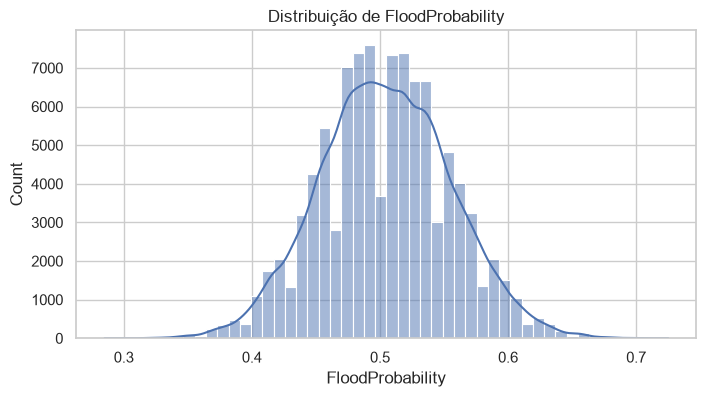

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df[TARGET], bins=50, kde=True, ax=ax)
ax.set_title("Distribuição de FloodProbability")
plt.show()

### 1.4 Fatores potencialmente associados ao risco de inundação

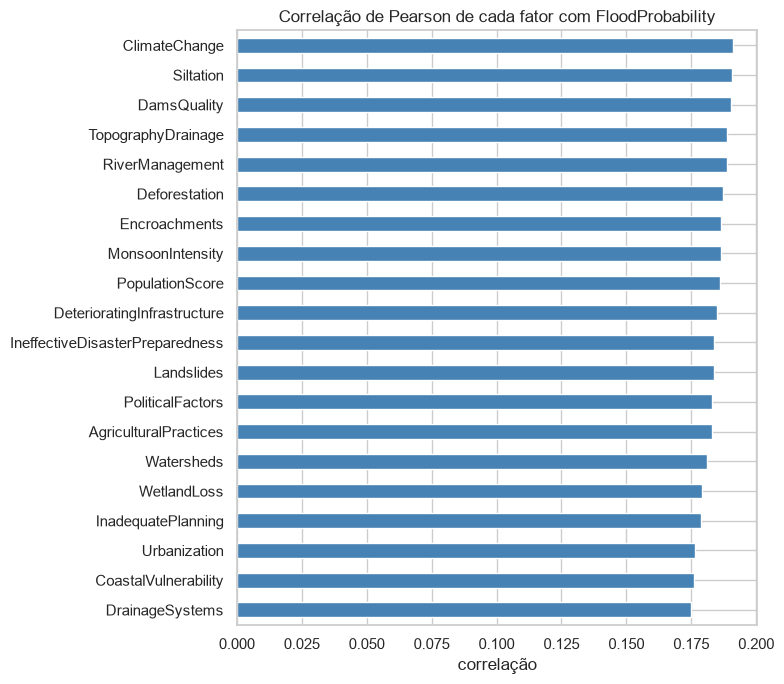

ClimateChange                      0.191
Siltation                          0.191
DamsQuality                        0.190
TopographyDrainage                 0.189
RiverManagement                    0.189
Deforestation                      0.187
Encroachments                      0.186
MonsoonIntensity                   0.186
PopulationScore                    0.186
DeterioratingInfrastructure        0.185
IneffectiveDisasterPreparedness    0.184
Landslides                         0.184
PoliticalFactors                   0.183
AgriculturalPractices              0.183
Watersheds                         0.181
WetlandLoss                        0.179
InadequatePlanning                 0.179
Urbanization                       0.176
CoastalVulnerability               0.176
DrainageSystems                    0.175
Name: FloodProbability, dtype: float64

In [7]:
corr = df[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
corr.plot.barh(ax=ax, color="steelblue")
ax.set_title("Correlação de Pearson de cada fator com FloodProbability")
ax.set_xlabel("correlação")
plt.tight_layout()
plt.show()
corr.sort_values(ascending=False).round(3)

Correlação da SOMA dos 20 fatores com o alvo: 0.919


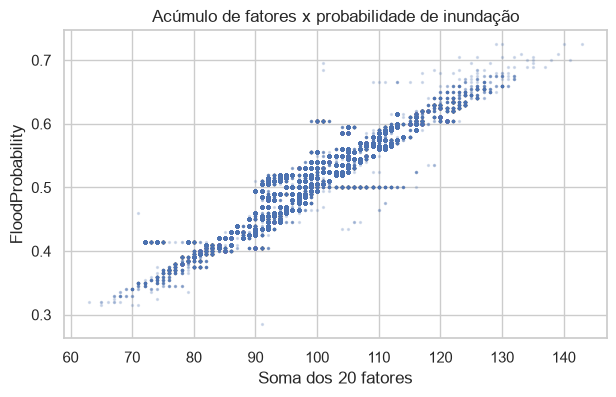

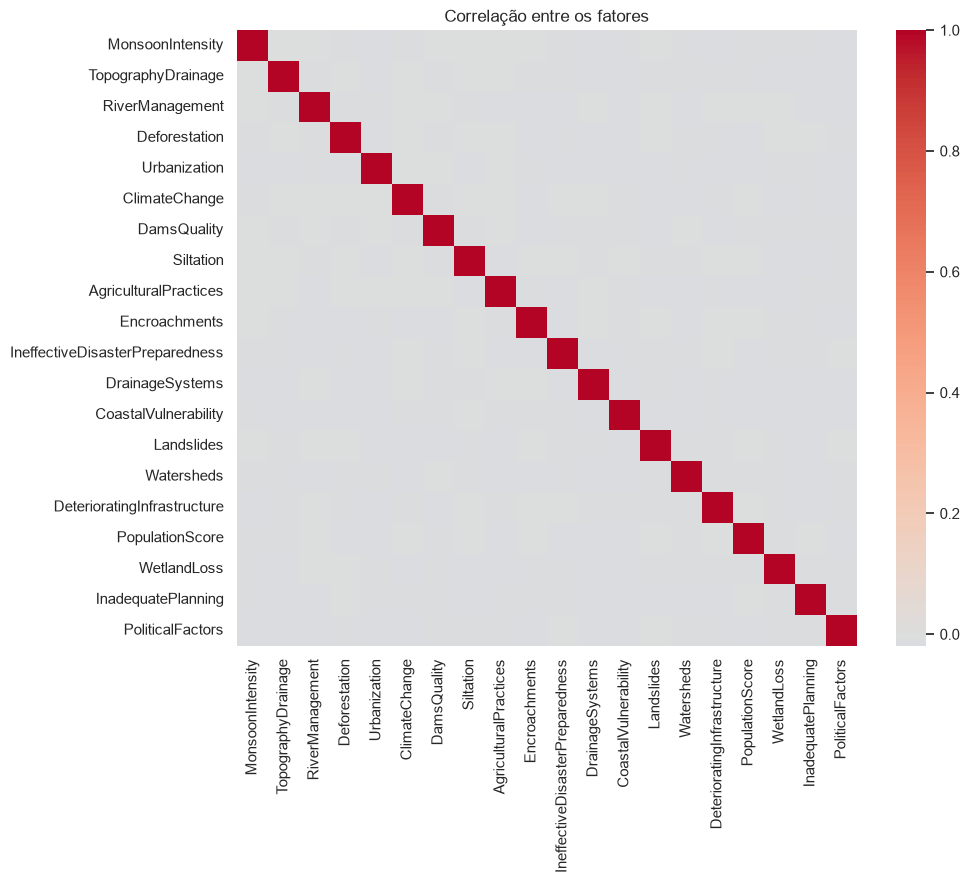

In [8]:
# Os fatores têm correlações individuais parecidas; verificamos se o "acúmulo" de fatores explica melhor o alvo
soma_fatores = df[FEATURES].sum(axis=1)
print(f"Correlação da SOMA dos 20 fatores com o alvo: {soma_fatores.corr(df[TARGET]):.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(soma_fatores, df[TARGET], s=2, alpha=0.2)
ax.set_xlabel("Soma dos 20 fatores")
ax.set_ylabel(TARGET)
ax.set_title("Acúmulo de fatores x probabilidade de inundação")
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(df[FEATURES].corr(), cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlação entre os fatores")
plt.show()

**Análise:** todos os 20 fatores têm correlação **positiva e de magnitude semelhante** com o alvo — nenhum fator isolado domina.
Destacam-se intensidade das monções, drenagem topográfica, gestão de rios, desmatamento, urbanização e mudanças climáticas, mas a
diferença entre eles é pequena. Já a **soma dos fatores** tem correlação muito mais alta: o risco cresce com o *acúmulo* de condições
desfavoráveis, o que sugere uma relação aproximadamente **aditiva e linear**. Os fatores praticamente não se correlacionam entre si
(heatmap quase neutro), então não há multicolinearidade relevante.

### 1.5 Preparação

In [9]:
n_antes = len(df)
df = df.drop_duplicates().dropna()
print(f"Linhas removidas (duplicadas/ausentes): {n_antes - len(df)}")

# 'id' é apenas um identificador: removido das entradas do modelo
X = df[FEATURES]
y = df[TARGET]
assert "id" not in X.columns
print("Entradas do modelo:", X.shape[1], "variáveis")

Linhas removidas (duplicadas/ausentes): 0
Entradas do modelo: 20 variáveis


## 2. Desenvolvimento dos modelos

In [10]:
# Divisão única (80/20) usada pelos DOIS modelos -> comparação justa.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Treino:", X_train.shape, " Teste:", X_test.shape)

Treino: (80000, 20)  Teste: (20000, 20)


Modelos escolhidos:
- **Regressão Linear** — simples, interpretável, adequada se a relação for aditiva (como indicou a análise exploratória).
- **Random Forest** — conjunto de árvores de decisão, captura não linearidades e interações.

Os modelos são ajustados **apenas com o conjunto de treino**; o teste é usado somente na avaliação.

In [11]:
modelos = {
    "Regressão Linear": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE),
}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print(f"{nome}: treinado")

Regressão Linear: treinado


Random Forest: treinado


## 3. Avaliação de desempenho (conjunto de teste)

In [12]:
previsoes, linhas = {}, []
for nome, modelo in modelos.items():
    p = modelo.predict(X_test)
    previsoes[nome] = p
    linhas.append({
        "Modelo": nome,
        "MAE": mean_absolute_error(y_test, p),
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "R²": r2_score(y_test, p),
    })
resultados = pd.DataFrame(linhas).set_index("Modelo")
resultados.style.format("{:.4f}").highlight_min(subset=["MAE", "RMSE"], color="lightgreen")

,MAE,RMSE,R²
Modelo,,,
Regressão Linear,0.0157,0.0199,0.8496
Random Forest,0.0270,0.0329,0.5893


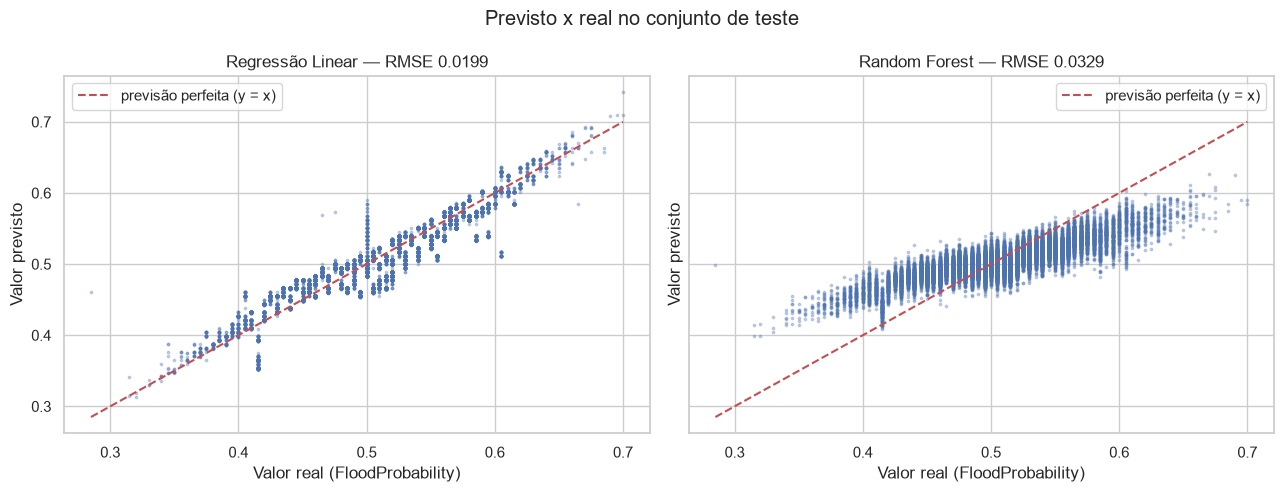

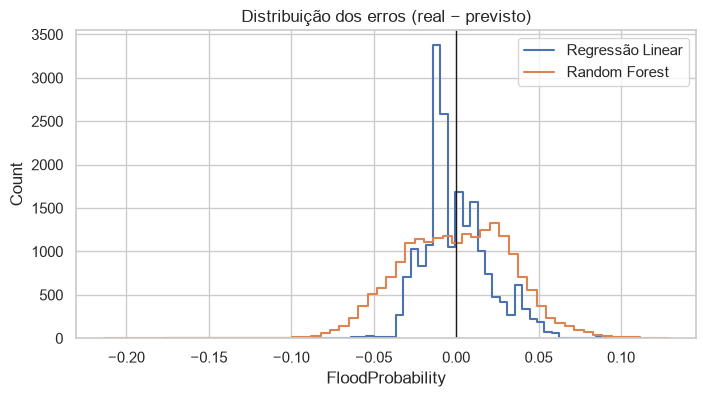

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
lim = [y_test.min(), y_test.max()]
for ax, (nome, p) in zip(axes, previsoes.items()):
    ax.scatter(y_test, p, s=3, alpha=0.3)
    ax.plot(lim, lim, "r--", label="previsão perfeita (y = x)")
    ax.set_title(f"{nome} — RMSE {resultados.loc[nome, 'RMSE']:.4f}")
    ax.set_xlabel("Valor real (FloodProbability)")
    ax.set_ylabel("Valor previsto")
    ax.legend()
plt.suptitle("Previsto x real no conjunto de teste")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for nome, p in previsoes.items():
    sns.histplot(y_test - p, bins=60, element="step", fill=False, label=nome, ax=ax)
ax.axvline(0, color="k", lw=1)
ax.set_title("Distribuição dos erros (real − previsto)")
ax.legend()
plt.show()

In [14]:
NOME_FINAL = resultados["RMSE"].idxmin()
modelo_final = modelos[NOME_FINAL]
print(f"Modelo final: {NOME_FINAL}")
print(resultados.loc[NOME_FINAL].round(4).to_string())

Modelo final: Regressão Linear
MAE     0.0157
RMSE    0.0199
R²      0.8496


**Justificativa da escolha:** o modelo final é o de **menor MAE e RMSE no conjunto de teste** (selecionado automaticamente na célula
acima). Com este dataset a **Regressão Linear** supera a Random Forest: como o alvo cresce de forma aproximadamente aditiva com
os fatores (vide análise da soma), uma reta descreve bem o fenômeno, enquanto as árvores aproximam essa relação em "degraus" e precisam
de muito mais dados/profundidade para chegar perto. Além do desempenho, a regressão linear é mais leve, rápida e interpretável
(cada coeficiente indica quanto um fator aumenta a probabilidade), o que facilita explicar os alertas.

O gráfico previsto x real mostra os pontos da regressão linear mais concentrados na diagonal; a Random Forest "achata" as previsões,
superestimando casos de baixo risco e subestimando casos de alto risco (justamente os mais importantes para alertas).

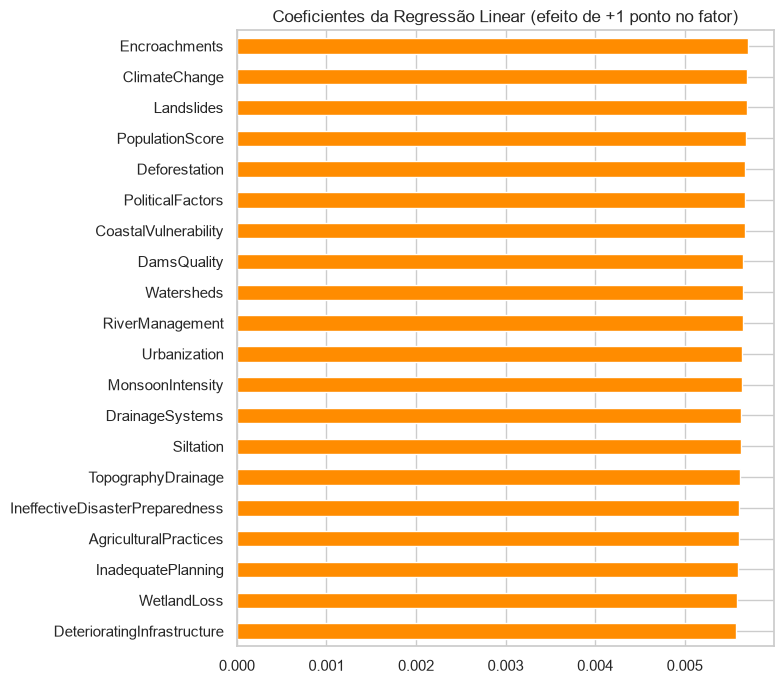

In [15]:
if NOME_FINAL == "Regressão Linear":
    coef = pd.Series(modelo_final.coef_, index=FEATURES).sort_values()
    titulo = "Coeficientes da Regressão Linear (efeito de +1 ponto no fator)"
else:
    coef = pd.Series(modelo_final.feature_importances_, index=FEATURES).sort_values()
    titulo = "Importância das variáveis (Random Forest)"
coef.plot.barh(figsize=(8, 7), color="darkorange", title=titulo)
plt.tight_layout()
plt.show()

## 4. Alertas de risco

### 4.1 Definição dos limites

Os limites são os **tercis (percentis 33 e 67) da variável-alvo no conjunto de TREINO**, arredondados em 2 casas:
- **Baixo:** previsão < limite inferior → um terço dos registros históricos com menor probabilidade
- **Médio:** entre os limites → faixa central, comportamento típico
- **Alto:** previsão ≥ limite superior → um terço dos registros com maior probabilidade

Justificativa: o dataset é sintético e não traz um critério físico/oficial de risco, então usamos uma divisão **relativa à própria
distribuição dos dados**, que gera três classes equilibradas e é calculada **sem usar o conjunto de teste**. São faixas didáticas.

In [16]:
LIMITE_BAIXO, LIMITE_ALTO = y_train.quantile([1/3, 2/3]).round(2).tolist()
print(f"Baixo: < {LIMITE_BAIXO} | Médio: {LIMITE_BAIXO} a {LIMITE_ALTO} | Alto: >= {LIMITE_ALTO}")

def classificar_risco(prob):
    if prob < LIMITE_BAIXO:
        return "BAIXO"
    if prob < LIMITE_ALTO:
        return "MÉDIO"
    return "ALTO"

assert classificar_risco(LIMITE_BAIXO - 0.01) == "BAIXO"
assert classificar_risco(LIMITE_BAIXO) == "MÉDIO"
assert classificar_risco(LIMITE_ALTO) == "ALTO"

Baixo: < 0.48 | Médio: 0.48 a 0.52 | Alto: >= 0.52


### 4.2 Demonstração com três cenários

In [17]:
def cenario(valor_base, **ajustes):
    c = {f: valor_base for f in FEATURES}
    c.update(ajustes)
    return c

CENARIOS = {
    "1 - Bairro planejado (fatores baixos)": cenario(4, DrainageSystems=3, DamsQuality=3, Urbanization=3),
    "2 - Cidade típica (fatores na mediana)": {f: int(X_train[f].median()) for f in FEATURES},
    "3 - Área crítica (monção forte, ocupação irregular)": cenario(
        6, MonsoonIntensity=9, Deforestation=8, Urbanization=8, Encroachments=8, DrainageSystems=8, ClimateChange=8),
}

def prever(entradas):
    prob = float(modelo_final.predict(pd.DataFrame([entradas])[FEATURES])[0])
    return prob, classificar_risco(prob)

demo = []
for nome, entradas in CENARIOS.items():
    prob, risco = prever(entradas)
    demo.append({"Cenário": nome, "Soma dos fatores": sum(entradas.values()),
                 "Probabilidade prevista": round(prob, 4), "Risco": risco})
demo = pd.DataFrame(demo).set_index("Cenário")
demo

,Soma dos fatores,Probabilidade prevista,Risco
Cenário,,,
1 - Bairro planejado (fatores baixos),77,0.3815,BAIXO
2 - Cidade típica (fatores na mediana),100,0.5113,MÉDIO
"3 - Área crítica (monção forte, ocupação irregular)",133,0.6979,ALTO


In [18]:
# Cenários reais do conjunto de teste (um de cada faixa), comparando previsão e valor real
exemplos = []
p_final = previsoes[NOME_FINAL]
for faixa in ["BAIXO", "MÉDIO", "ALTO"]:
    idx = next(i for i, p in enumerate(p_final) if classificar_risco(p) == faixa)
    exemplos.append({"Faixa prevista": faixa, "Previsto": round(p_final[idx], 4),
                     "Real": round(y_test.iloc[idx], 4), "Faixa real": classificar_risco(y_test.iloc[idx])})
pd.DataFrame(exemplos)

,Faixa prevista,Previsto,Real,Faixa real
0,BAIXO,0.4716,0.48,MÉDIO
1,MÉDIO,0.4882,0.50,MÉDIO
2,ALTO,0.5224,0.54,ALTO


### 4.3 Interface interativa no notebook
Ajuste os fatores (ou escolha um cenário pronto) e clique em **Prever**. Requer `ipywidgets` (Jupyter/VS Code).
A mesma lógica também está disponível como aplicação web em `app.py` (Streamlit) — ver seção 4.4.

In [19]:
import ipywidgets as w
from IPython.display import display, HTML

CORES = {"BAIXO": "#2e7d32", "MÉDIO": "#f9a825", "ALTO": "#c62828"}
sliders = {f: w.IntSlider(value=int(X_train[f].median()), min=0, max=int(X[f].max()), description=f,
                          style={"description_width": "190px"}, layout=w.Layout(width="420px")) for f in FEATURES}
seletor = w.Dropdown(options=["(manual)"] + list(CENARIOS), description="Cenário:")
botao = w.Button(description="Prever", button_style="primary")
saida = w.Output()

def aplicar_cenario(change):
    if change["new"] in CENARIOS:
        for f, v in CENARIOS[change["new"]].items():
            sliders[f].value = v

def ao_prever(_):
    prob, risco = prever({f: s.value for f, s in sliders.items()})
    with saida:
        saida.clear_output()
        display(HTML(f"<h3>Probabilidade prevista: {prob:.3f} — "
                     f"<span style='color:{CORES[risco]}'>RISCO {risco}</span></h3>"
                     "<small>Dados sintéticos; faixas didáticas, sem validação operacional.</small>"))

seletor.observe(aplicar_cenario, names="value")
botao.on_click(ao_prever)
display(w.VBox([seletor, w.GridBox(list(sliders.values()), layout=w.Layout(grid_template_columns="repeat(2, 430px)")),
                botao, saida]))

### 4.4 Exportação para a interface web
O modelo final, os limites e os cenários são salvos em `modelo_inundacao.joblib`, usado pela aplicação `app.py`:

```
streamlit run app.py
```

In [20]:
joblib.dump({
    "modelo": modelo_final,
    "nome_modelo": NOME_FINAL,
    "features": FEATURES,
    "limites": (LIMITE_BAIXO, LIMITE_ALTO),
    "cenarios": CENARIOS,
    "medianas": {f: int(X_train[f].median()) for f in FEATURES},
    "maximos": {f: int(X[f].max()) for f in FEATURES},
    "metricas": resultados.loc[NOME_FINAL].to_dict(),
}, "modelo_inundacao.joblib")
print("Salvo em modelo_inundacao.joblib")

Salvo em modelo_inundacao.joblib


## 5. Limitações

Acerto da faixa de risco: 73.3%
Falsos alarmes (previsto ALTO, real não-ALTO): 1.7% dos casos
Riscos não sinalizados (real ALTO, previsto não-ALTO): 7.7% dos casos


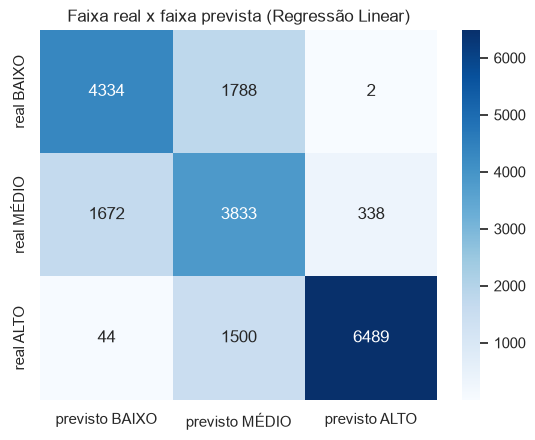

In [21]:
# Quanto o erro de regressão se traduz em erro de ALERTA no conjunto de teste
ordem = ["BAIXO", "MÉDIO", "ALTO"]
real_cls = [classificar_risco(v) for v in y_test]
prev_cls = [classificar_risco(v) for v in p_final]
cm = pd.DataFrame(confusion_matrix(real_cls, prev_cls, labels=ordem),
                  index=[f"real {o}" for o in ordem], columns=[f"previsto {o}" for o in ordem])

acerto = np.mean(np.array(real_cls) == np.array(prev_cls))
falso_alarme = np.mean([(r != "ALTO") and (p == "ALTO") for r, p in zip(real_cls, prev_cls)])
nao_sinalizado = np.mean([(r == "ALTO") and (p != "ALTO") for r, p in zip(real_cls, prev_cls)])
print(f"Acerto da faixa de risco: {acerto:.1%}")
print(f"Falsos alarmes (previsto ALTO, real não-ALTO): {falso_alarme:.1%} dos casos")
print(f"Riscos não sinalizados (real ALTO, previsto não-ALTO): {nao_sinalizado:.1%} dos casos")

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"Faixa real x faixa prevista ({NOME_FINAL})")
plt.show()

**Erros de previsão e alertas.** O RMSE do modelo é pequeno em termos absolutos, mas é **comparável à largura da faixa "médio"**.
Por isso, cenários com valor real próximo de um limite podem ser jogados para a faixa vizinha:
- **Falso alarme** (superestimação): o modelo indica risco ALTO onde ele não existe → mobilização desnecessária, custos e perda de
  confiança da população nos alertas ("efeito boy who cried wolf").
- **Risco não sinalizado** (subestimação): o modelo indica BAIXO/MÉDIO numa situação de risco ALTO → é o erro mais grave, pois pode
  deixar de acionar evacuação, bloqueio de vias ou preparação dos serviços essenciais.

A matriz acima mostra que quase todos os erros acontecem entre faixas **vizinhas** (quase nunca BAIXO ↔ ALTO), mas ainda assim existem.
Em um sistema real, seria preferível **ajustar o limite do ALTO para baixo** (aceitar mais falsos alarmes para perder menos riscos) e
exibir a incerteza (ex.: previsão ± RMSE) junto do alerta.

**Outras limitações:**
- **Os dados são sintéticos** (gerados para uma competição do Kaggle a partir de outro dataset); os fatores são escalas abstratas, sem
  unidade física, local ou data. O modelo **não** aprendeu hidrologia real.
- **As faixas de alerta são didáticas** (tercis da amostra), **sem validação para uso operacional** — não substituem órgãos como a
  Defesa Civil, que usam chuva medida, nível de rios, previsão meteorológica e mapeamento de áreas de risco.
- Foi usada uma amostra de 100 mil linhas; os fatores são inteiros e limitados ao intervalo visto no treino — cenários fora desse
  intervalo são extrapolação.
- Não há dimensão temporal nem espacial (o risco real muda hora a hora com a chuva).

## Conclusão
O modelo final é o indicado na seção 3 (Regressão Linear, de menor MAE/RMSE), que explica bem a relação aproximadamente aditiva entre os
fatores e a probabilidade de inundação. As previsões são convertidas em risco baixo/médio/alto pelos tercis do treino e podem ser
consultadas no notebook (widgets) ou na aplicação `app.py`. O protótipo é apenas educacional: dados sintéticos e faixas didáticas.